# PBI, balanza comercial e tipo de cambio real

Flujo trimestral 2004-I--2026-II para estudiar el impacto dinámico del saldo de la balanza comercial sobre el PBI real de Argentina. La estrategia se organiza según los objetivos de la investigación: (1) propiedades estocásticas, integración y cointegración; (2) causalidad de Granger y ajuste de corto plazo; y (3) respuesta del PBI a innovaciones de la balanza mediante IRF y FEVD.

Catelán (2025) se utiliza como referencia metodológica, no como una especificación que deba copiarse. El úmero de rezagos, la existencia de cointegración y la elección entre VAR/VECM se determinan con la evidencia de esta base trimestral.

In [57]:
from pathlib import Path
import warnings
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from statsmodels.tsa.stattools import adfuller, kpss, zivot_andrews
from statsmodels.tsa.api import VAR
from statsmodels.tsa.vector_ar.vecm import VECM, coint_johansen, select_coint_rank
from statsmodels.stats.diagnostic import acorr_ljungbox

warnings.filterwarnings('ignore')
plt.style.use('seaborn-v0_8-whitegrid')
pd.set_option('display.max_columns', 30)
DATA_CANDIDATES = [Path.cwd() / 'dt.csv', Path.cwd() / 'python' / 'dt.csv', Path.cwd() / 'TIF' / 'python' / 'dt.csv', Path.cwd() / 'TIF' / 'main' / 'dtt.csv', Path.cwd() / 'main' / 'dtt.csv', Path.cwd() / 'main' / 'dt.csv', Path.cwd().parent / 'main' / 'dtt.csv', Path.cwd().parent / 'main' / 'dt.csv']
DATA_PATH = next((p.resolve() for p in DATA_CANDIDATES if p.exists()), None)
if DATA_PATH is None:
    raise FileNotFoundError('No se encontró dt.csv o dtt.csv desde el directorio de ejecución.')
DATA_PATH

WindowsPath('C:/Users/atili/OneDrive - unsa.edu.pe/UNSA/SEMESTER 6/ECONOMY INTERNATIONAL/TIF/python/dt.csv')

## 1. Preparación

El PBI y el tipo de cambio real se expresan en logaritmos. La balanza comercial puede ser negativa y no se transforma con logaritmo; se usa el saldo relativo al PBI (`bc_pbi`), coherente con la razón de balanza comercial/PBI usada por Catelén.

In [58]:
df = pd.read_csv(DATA_PATH, thousands=',', parse_dates=['fecha'])
df = df.sort_values('fecha').set_index('fecha')
numeric = ['pib', 'importaciones', 'exportaciones', 'bc', 'tc_real', 'covid']
for col in numeric:
    df[col] = pd.to_numeric(df[col], errors='raise')
if df.index.duplicated().any() or df.isna().any().any():
    raise ValueError('dt.csv tiene fechas duplicadas o valores faltantes.')
if (df[['pib', 'tc_real']] <= 0).any().any():
    raise ValueError('PBI e ITCRM deben ser positivos para aplicar logaritmos.')
df['bc_pbi'] = df['bc'] / df['pib']
df['ln_pib'] = np.log(df['pib'])
df['ln_tc_real'] = np.log(df['tc_real'])
df.index = pd.DatetimeIndex(df.index, freq='QE-DEC')
series = df[['ln_pib', 'bc_pbi', 'ln_tc_real']]
exog = df[['covid']].astype(float)
display(df[['pib', 'bc', 'bc_pbi', 'tc_real', 'covid']].head())
print('Observaciones:', len(df), '| inicio:', df.index.min().date(), '| fin:', df.index.max().date())

,pib,bc,bc_pbi,tc_real,covid
fecha,,,,,
2004-03-31,475537.70,34732.10,0.073038,159.021978,0
2004-06-30,470384.94,34779.42,0.073938,153.019780,0
2004-09-30,493754.15,34536.32,0.069946,158.467391,0
2004-12-31,500783.99,31834.72,0.063570,163.419565,0
2005-03-31,515273.14,41547.14,0.080631,162.242222,0


Observaciones: 90 | inicio: 2004-03-31 | fin: 2026-06-30


In [59]:
RESULTS_DIR = DATA_PATH.parent.parent / 'python' / 'results'
RESULTS_DIR.mkdir(parents=True, exist_ok=True)
# Se reservan los últimos 8 trimestres para evaluación; el entrenamiento usa automáticamente el resto.
ENDOGENOUS = ['ln_pib', 'bc_pbi', 'ln_tc_real']
EXOGENOUS = ['covid']
HOLDOUT_QUARTERS = 8  # Dos años completos, no un úmero arbitrario
if HOLDOUT_QUARTERS < 4 or HOLDOUT_QUARTERS >= len(df) - 20:
    raise ValueError('El holdout debe dejar una muestra de entrenamiento suficiente.')
train_df = df.iloc[:-HOLDOUT_QUARTERS].copy()
test_df = df.iloc[-HOLDOUT_QUARTERS:].copy()
train_series = train_df[ENDOGENOUS]
test_series = test_df[ENDOGENOUS]
train_exog = train_df[EXOGENOUS]
test_exog = test_df[EXOGENOUS]
print('Endógenas:', ENDOGENOUS)
print('Exógenas:', EXOGENOUS)
print('Entrenamiento:', train_df.index.min().date(), 'a', train_df.index.max().date(), '|', len(train_df), 'observaciones')
print('Holdout:', test_df.index.min().date(), 'a', test_df.index.max().date(), '|', len(test_df), 'observaciones')


Endógenas: ['ln_pib', 'bc_pbi', 'ln_tc_real']
Exógenas: ['covid']
Entrenamiento: 2004-03-31 a 2024-06-30 | 82 observaciones
Holdout: 2024-09-30 a 2026-06-30 | 8 observaciones


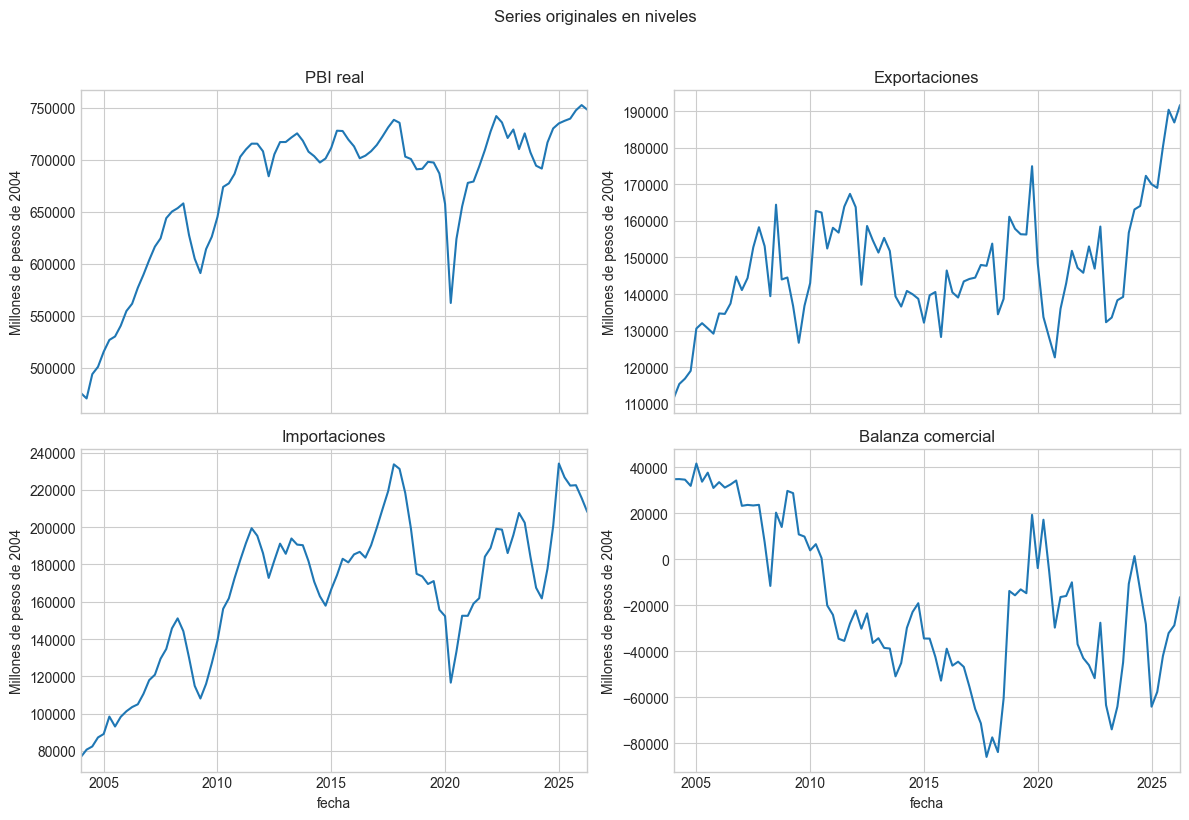

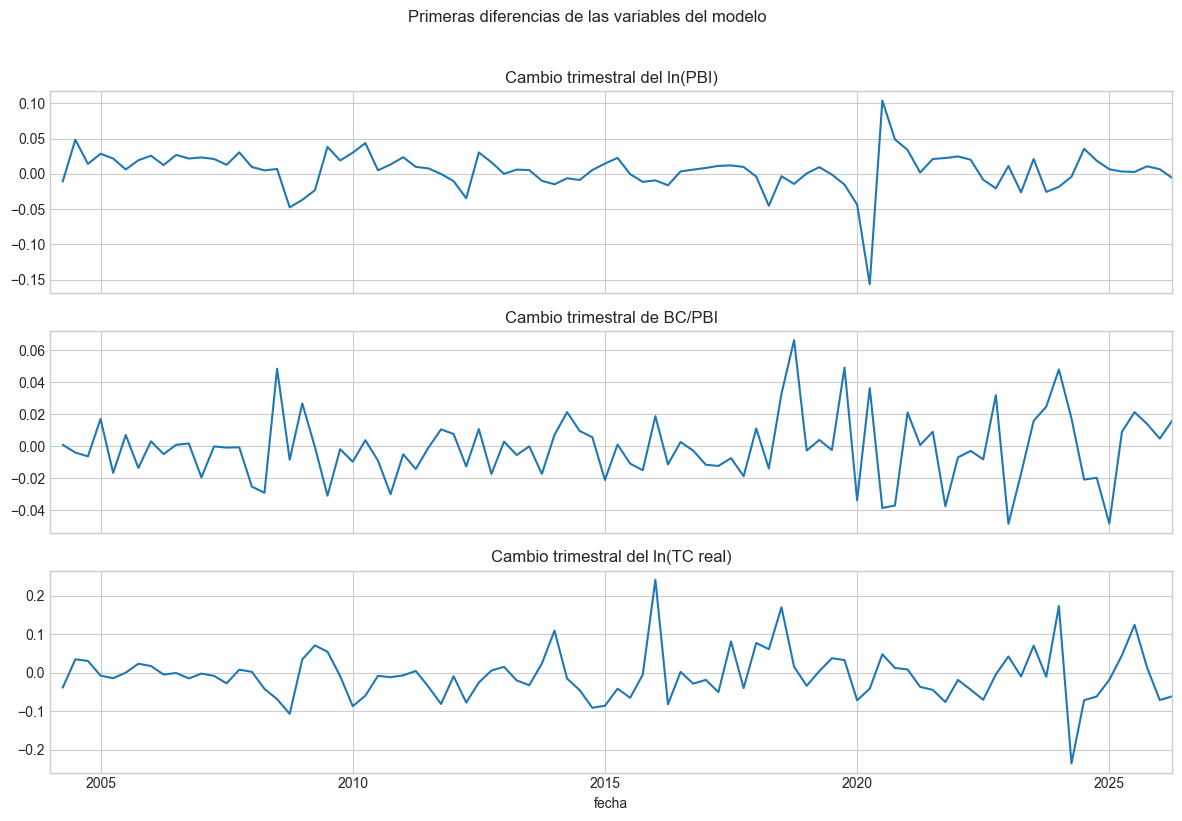

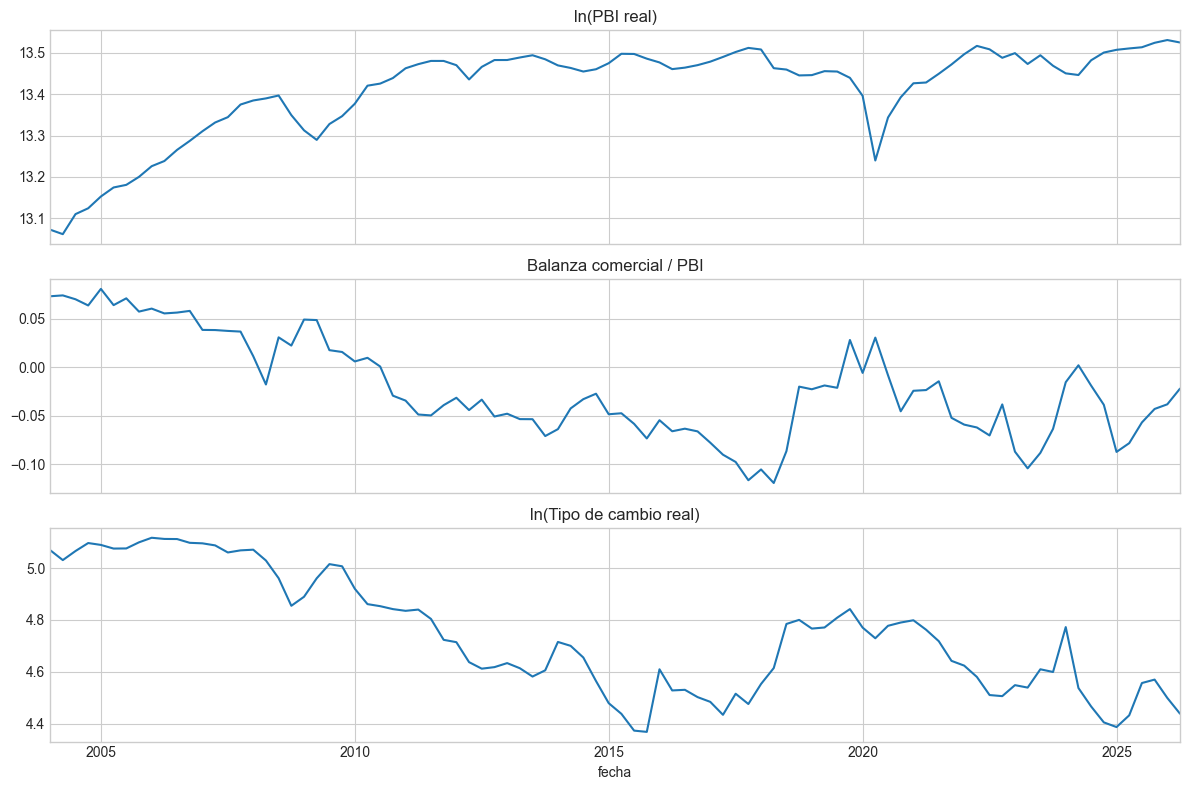

In [60]:
IMG_DIR = DATA_PATH.parent.parent / 'python' / 'results' / 'img'
IMG_DIR.mkdir(parents=True, exist_ok=True)
# Niveles en unidades originales: PBI, exportaciones, importaciones y saldo comercial.
raw_cols = ['pib', 'exportaciones', 'importaciones', 'bc']
raw_labels = ['PBI real', 'Exportaciones', 'Importaciones', 'Balanza comercial']
fig, axes = plt.subplots(2, 2, figsize=(12, 8), sharex=True)
for ax, col, label in zip(axes.ravel(), raw_cols, raw_labels):
    df[col].plot(ax=ax, title=label)
    ax.set_ylabel('Millones de pesos de 2004')
fig.suptitle('Series originales en niveles', y=1.02)
fig.tight_layout()
fig.savefig(IMG_DIR / 'series_niveles_originales.png', dpi=300, bbox_inches='tight')
plt.show()

# Las diferencias muestran los cambios trimestrales y ayudan a comprobar estabilidad.
fig, axes = plt.subplots(3, 1, figsize=(12, 8), sharex=True)
for ax, col, title in zip(axes, series.columns, ['Cambio trimestral del ln(PBI)', 'Cambio trimestral de BC/PBI', 'Cambio trimestral del ln(TC real)']):
    series[col].diff().plot(ax=ax, title=title)
fig.suptitle('Primeras diferencias de las variables del modelo', y=1.02)
fig.tight_layout()
fig.savefig(IMG_DIR / 'series_primeras_diferencias.png', dpi=300, bbox_inches='tight')
plt.show()

# Niveles transformados utilizados por el modelo.
fig, axes = plt.subplots(3, 1, figsize=(12, 8), sharex=True)
for ax, col, title in zip(axes, series.columns, ['ln(PBI real)', 'Balanza comercial / PBI', 'ln(Tipo de cambio real)']):
    series[col].plot(ax=ax, title=title)
fig.tight_layout()
fig.savefig(IMG_DIR / 'series_modelo.png', dpi=300, bbox_inches='tight')
plt.show()

## 2. Pruebas de raíz unitaria

Se utiliza un nivel de significancia de 5% (α = 0.05).

### ADF (Dickey-Fuller aumentado)

- **H0:** la serie tiene raíz unitaria; no es estacionaria.
- **H1:** la serie es estacionaria.
- **Regla:** si `p < 0.05`, se rechaza H0; si `p >= 0.05`, no se rechaza H0.

### KPSS

- **H0:** la serie es estacionaria.
- **H1:** la serie no es estacionaria.
- **Regla:** si `p < 0.05`, se rechaza H0; si `p >= 0.05`, no se rechaza H0.

### Decisión conjunta

- Si ADF rechaza H0 y KPSS no rechaza H0, la serie se considera estacionaria, I(0).
- Si ADF no rechaza H0 y KPSS rechaza H0, la serie se considera no estacionaria.
- Si ambas pruebas no coinciden, el resultado es inconcluso y debe revisarse antes de elegir el modelo.

### Zivot-Andrews

- **H0:** la serie tiene raíz unitaria considerando una ruptura estructural.
- **H1:** la serie es estacionaria considerando una ruptura estructural.
- **Regla:** si `p < 0.05`, se rechaza H0; si `p >= 0.05`, no se rechaza H0.

La interpretación de los valores obtenidos se imprime en la consola después de la tabla.

In [61]:
def unit_root_report(x):
    x = pd.Series(x).dropna()
    rows = {}
    for label, values in [('nivel', x), ('primera_diferencia', x.diff().dropna())]:
        adf = adfuller(values, regression='ct', autolag='AIC')
        try:
            kps = kpss(values, regression='ct', nlags='auto')
            kpss_stat, kpss_p = kps[0], kps[1]
        except ValueError:
            kpss_stat, kpss_p = np.nan, np.nan
        rows[label] = {'ADF_stat': adf[0], 'ADF_p': adf[1], 'ADF_lags': adf[2], 'KPSS_stat': kpss_stat, 'KPSS_p': kpss_p}
    za = zivot_andrews(x, regression='ct', autolag='AIC')
    rows['ZA_nivel'] = {'ADF_stat': za[0], 'ADF_p': za[1], 'ADF_lags': za[2], 'KPSS_stat': np.nan, 'KPSS_p': np.nan, 'ZA_break_index': za[3], 'ZA_break_date': x.index[za[3]]}
    return pd.DataFrame(rows).T

def interpret_unit_roots(table, alpha=0.05):
    for period in ['nivel', 'primera_diferencia']:
        row = table.loc[period]
        adf_rejects = row['ADF_p'] < alpha
        kpss_rejects = row['KPSS_p'] < alpha
        print(f'\n[{period}]')
        print(f'ADF: p = {row["ADF_p"]:.4f} -> ' + ('rechazar H0: evidencia de estacionariedad.' if adf_rejects else 'no rechazar H0: posible raíz unitaria.'))
        print(f'KPSS: p = {row["KPSS_p"]:.4f} -> ' + ('rechazar H0: evidencia de no estacionariedad.' if kpss_rejects else 'no rechazar H0: estacionariedad no rechazada.'))
        if adf_rejects and not kpss_rejects:
            print('Decisión conjunta: la serie se considera estacionaria en este periodo, I(0).')
        elif not adf_rejects and kpss_rejects:
            print('Decisión conjunta: la serie se considera no estacionaria en este periodo.')
        else:
            print('Decisión conjunta: las pruebas no coinciden; revisar la especificación antes de clasificarla.')
    za = table.loc['ZA_nivel']
    print(f'Prueba: p = {za["ADF_p"]:.4f} -> ' + ('rechazar H0: evidencia de estacionariedad con ruptura.' if za['ADF_p'] < alpha else 'no rechazar H0: no hay evidencia suficiente para descartar raíz unitaria con ruptura.'))

ur_tables = {name: unit_root_report(series[name]) for name in series}
for name, table in ur_tables.items():
    print(f'--- {name} ---')
    display(table)
    interpret_unit_roots(table)


--- ln_pib ---


,ADF_stat,ADF_p,ADF_lags,KPSS_stat,KPSS_p,ZA_break_index,ZA_break_date
nivel,-3.263165,0.072534,1.0,0.288354,0.01,NaN,NaN
primera_diferencia,-8.416081,0.0,0.0,0.077834,0.1,NaN,NaN
ZA_nivel,-3.797481,0.637451,"{'1%': -5.57556, '5%': -5.07332, '10%': -4.82668}",NaN,NaN,1,2004-06-30 00:00:00



[nivel]
ADF: p = 0.0725 -> no rechazar H0: posible raíz unitaria.
KPSS: p = 0.0100 -> rechazar H0: evidencia de no estacionariedad.
Decisión conjunta: la serie se considera no estacionaria en este periodo.

[primera_diferencia]
ADF: p = 0.0000 -> rechazar H0: evidencia de estacionariedad.
KPSS: p = 0.1000 -> no rechazar H0: estacionariedad no rechazada.
Decisión conjunta: la serie se considera estacionaria en este periodo, I(0).
Prueba: p = 0.6375 -> no rechazar H0: no hay evidencia suficiente para descartar raíz unitaria con ruptura.
--- bc_pbi ---


,ADF_stat,ADF_p,ADF_lags,KPSS_stat,KPSS_p,ZA_break_index,ZA_break_date
nivel,-2.530647,0.312813,0.0,0.273411,0.01,NaN,NaN
primera_diferencia,-6.629266,0.0,3.0,0.022952,0.1,NaN,NaN
ZA_nivel,-5.295365,0.025187,"{'1%': -5.57556, '5%': -5.07332, '10%': -4.82668}",NaN,NaN,0,2004-03-31 00:00:00



[nivel]
ADF: p = 0.3128 -> no rechazar H0: posible raíz unitaria.
KPSS: p = 0.0100 -> rechazar H0: evidencia de no estacionariedad.
Decisión conjunta: la serie se considera no estacionaria en este periodo.

[primera_diferencia]
ADF: p = 0.0000 -> rechazar H0: evidencia de estacionariedad.
KPSS: p = 0.1000 -> no rechazar H0: estacionariedad no rechazada.
Decisión conjunta: la serie se considera estacionaria en este periodo, I(0).
Prueba: p = 0.0252 -> rechazar H0: evidencia de estacionariedad con ruptura.
--- ln_tc_real ---


,ADF_stat,ADF_p,ADF_lags,KPSS_stat,KPSS_p,ZA_break_index,ZA_break_date
nivel,-2.148257,0.518991,0.0,0.230974,0.01,NaN,NaN
primera_diferencia,-6.415825,0.0,2.0,0.050089,0.1,NaN,NaN
ZA_nivel,-4.793345,0.109304,"{'1%': -5.57556, '5%': -5.07332, '10%': -4.82668}",NaN,NaN,0,2004-03-31 00:00:00



[nivel]
ADF: p = 0.5190 -> no rechazar H0: posible raíz unitaria.
KPSS: p = 0.0100 -> rechazar H0: evidencia de no estacionariedad.
Decisión conjunta: la serie se considera no estacionaria en este periodo.

[primera_diferencia]
ADF: p = 0.0000 -> rechazar H0: evidencia de estacionariedad.
KPSS: p = 0.1000 -> no rechazar H0: estacionariedad no rechazada.
Decisión conjunta: la serie se considera estacionaria en este periodo, I(0).
Prueba: p = 0.1093 -> no rechazar H0: no hay evidencia suficiente para descartar raíz unitaria con ruptura.


## 3. Ruptura estructural

La fecha de Zivot--Andrews es un diagnóstico de una ruptura endógena única. No se eliminan observaciones. Una ruptura validada por teoría se incorpora como dummy de pulso o escalón. COVID se mantiene como exógena porque ya tiene una justificación económica y está en la base.

In [62]:
break_dates = {}
for name in series:
    za = zivot_andrews(series[name], regression='ct', autolag='AIC')
    break_dates[name] = series.index[za[3]]
display(pd.Series(break_dates, name='fecha_sugerida_Zivot_Andrews'))

def step_dummy(index, break_date):
    return pd.Series((index >= pd.Timestamp(break_date)).astype(float), index=index)

# No se activa automáticamente una dummy ZA: debe validarse históricamente.
# Ejemplo: exog['ruptura_2018Q1'] = step_dummy(df.index, '2018-03-31')
exog.head()

ln_pib       2004-06-30
bc_pbi       2004-03-31
ln_tc_real   2004-03-31
Name: fecha_sugerida_Zivot_Andrews, dtype: datetime64[us]

,covid
fecha,
2004-03-31,0.0
2004-06-30,0.0
2004-09-30,0.0
2004-12-31,0.0
2005-03-31,0.0


## 4. Selección de rezagos

Los criterios AIC, BIC, HQIC y FPE se utilizan para seleccionar el orden `p` del VAR en niveles.

- Cada criterio selecciona el número de rezagos que minimiza su propio valor.
- Si varios criterios seleccionan el mismo `p`, la decisión es más robusta.
- Si los criterios difieren, se comparan los modelos mediante autocorrelación residual, estabilidad y coherencia económica.

Para un VECM, el número de rezagos de las diferencias es `k_ar_diff = p - 1`. La interpretación de la selección se imprime después de la tabla de criterios.

In [63]:
lag_selection = VAR(train_series, exog=train_exog).select_order(maxlags=8, trend='ct')
print(lag_selection.summary())
selected_lag = max(int(lag_selection.aic), 1)
print('Rezago elegido por AIC:', selected_lag)

criteria_values = {'AIC': lag_selection.aic, 'BIC': lag_selection.bic, 'HQIC': lag_selection.hqic, 'FPE': lag_selection.fpe}
print('Rezagos seleccionados por criterio:', criteria_values)


 VAR Order Selection (* highlights the minimums) 
      AIC         BIC         FPE         HQIC   
-------------------------------------------------
0      -17.97      -17.69   1.570e-08      -17.86
1     -20.80*     -20.24*  9.256e-10*     -20.58*
2      -20.77      -19.93   9.548e-10      -20.44
3      -20.69      -19.57   1.047e-09      -20.24
4      -20.51      -19.11   1.255e-09      -19.95
5      -20.34      -18.66   1.508e-09      -19.67
6      -20.35      -18.39   1.519e-09      -19.57
7      -20.35      -18.11   1.555e-09      -19.46
8      -20.27      -17.75   1.745e-09      -19.27
-------------------------------------------------
Rezago elegido por AIC: 1
Rezagos seleccionados por criterio: {'AIC': np.int64(1), 'BIC': np.int64(1), 'HQIC': np.int64(1), 'FPE': np.int64(1)}


## 5. Estacionariedad, Johansen y elección VAR/VECM

La prueba de Johansen se aplica cuando las variables endógenas son I(1).

### Prueba de traza de Johansen

Para cada rango `r`:

- **H0:** el rango de cointegración es como máximo `r` (`rank <= r`).
- **H1:** el rango de cointegración es mayor que `r` (`rank > r`).
- **Regla:** si el estadístico de traza es mayor que el valor crítico al 5%, se rechaza H0. Si es menor o igual, no se rechaza H0.
- **Decisión:** se avanza desde `r = 0` y el rango seleccionado es el primer `r` cuyo H0 no se rechaza.

### Elección del modelo

- Variables I(0) → VAR en niveles.
- Variables I(1) y rango `r = 0` → VAR en primeras diferencias.
- Variables I(1) y `0 < r < k` → VECM.
- Variables I(1) y rango completo `r = k` → resultado que debe revisarse antes de estimar un VAR en niveles.

La interpretación de cada fila y la decisión del rango se imprime en la consola después de la tabla.

In [64]:
# Configuración principal: puede cambiarse después de comparar especificaciones determinísticas.
JOHANSEN_DET_ORDER = 0  # -1: sin determinísticos; 0: constante; 1: tendencia lineal
ALPHA = 0.05
k_ar_diff = max(int(selected_lag) - 1, 0)

def classify_integration(table, alpha=ALPHA):
    level = table.loc['nivel']
    difference = table.loc['primera_diferencia']
    level_stationary = level['ADF_p'] < alpha and level['KPSS_p'] > alpha
    difference_stationary = difference['ADF_p'] < alpha and difference['KPSS_p'] > alpha
    if level_stationary:
        return 0
    if difference_stationary:
        return 1
    return None

integration_orders = {name: classify_integration(table) for name, table in ur_tables.items()}
print('Órdenes de integración inferidos:', integration_orders)
if any(order is None for order in integration_orders.values()):
    raise ValueError('Alguna serie no tiene una clasificación I(0)/I(1) clara con ADF y KPSS; revise las pruebas antes de estimar el modelo.')
orders = set(integration_orders.values())
if len(orders) > 1:
    raise ValueError('Las variables no tienen el mismo orden de integración; no se puede aplicar Johansen directamente a este sistema.')

johansen = None
rank = None
johansen_table = pd.DataFrame()
if orders == {1}:
    johansen = coint_johansen(train_series, det_order=JOHANSEN_DET_ORDER, k_ar_diff=k_ar_diff)
    k = train_series.shape[1]
    johansen_table = pd.DataFrame({
        'r': range(k),
        'trace': johansen.lr1,
        'crit_90': johansen.cvt[:, 0],
        'crit_95': johansen.cvt[:, 1],
        'crit_99': johansen.cvt[:, 2],
    })
    johansen_table['rechaza_H0_5pct'] = johansen_table['trace'] > johansen_table['crit_95']
    display(johansen_table)
    print('Decisión: se rechaza H0 cuando trace > crit_95; el rango es el primer r cuyo H0 no se rechaza.')
    rank = int(select_coint_rank(
        train_series,
        det_order=JOHANSEN_DET_ORDER,
        k_ar_diff=k_ar_diff,
        method='trace',
        signif=ALPHA,
    ).rank)
    print(f'Rango de cointegración seleccionado al {int((1 - ALPHA) * 100)}%: {rank}')
else:
    print('Las variables se clasifican como I(0); no se necesita una prueba de cointegración para elegir el modelo.')

# La prueba adicional solicitada permite comprobar si el rango es robusto a los determinísticos.
sensitivity_rows = []
if orders == {1}:
    for det_order in [-1, 0, 1]:
        result = coint_johansen(train_series, det_order=det_order, k_ar_diff=k_ar_diff)
        selected_rank = int(select_coint_rank(train_series, det_order=det_order, k_ar_diff=k_ar_diff, method='trace', signif=ALPHA).rank)
        sensitivity_rows.append({'det_order': det_order, 'rango_trace_5pct': selected_rank})
    display(pd.DataFrame(sensitivity_rows))


Órdenes de integración inferidos: {'ln_pib': 1, 'bc_pbi': 1, 'ln_tc_real': 1}


,r,trace,crit_90,crit_95,crit_99,rechaza_H0_5pct
0,0,49.587112,27.0669,29.7961,35.4628,True
1,1,10.816351,13.4294,15.4943,19.9349,False
2,2,0.016559,2.7055,3.8415,6.6349,False


Decisión: se rechaza H0 cuando trace > crit_95; el rango es el primer r cuyo H0 no se rechaza.
Rango de cointegración seleccionado al 95%: 1


,det_order,rango_trace_5pct
0,-1,1
1,0,1
2,1,1


In [65]:
# Decisión automática basada en integración y rango de Johansen.
diff_series = train_series.diff().dropna()
model_kind = None
if orders == {0}:
    model_kind = 'VAR_niveles_I0'
    fitted = VAR(train_series, exog=train_exog).fit(maxlags=selected_lag, trend='ct')
elif rank == 0:
    model_kind = 'VAR_diferencias_sin_cointegracion'
    fitted = VAR(diff_series, exog=train_exog.iloc[1:]).fit(maxlags=selected_lag, trend='c')
elif 0 < rank < train_series.shape[1]:
    model_kind = 'VECM'
    # En VECM, el úmero de rezagos de diferencias es p - 1.
    # Con p=1, k_ar_diff=0 es correcto y no se agrega un rezago artificial.
    vecm_deterministic = { -1: 'n', 0: 'co', 1: 'lo' }[JOHANSEN_DET_ORDER]
    fitted = VECM(
        endog=train_series,
        exog=train_exog,
        k_ar_diff=k_ar_diff,
        coint_rank=rank,
        deterministic=vecm_deterministic,
    ).fit()
elif rank == train_series.shape[1]:
    raise ValueError('Johansen indica rango completo aunque las series fueron clasificadas como I(1). Revise determinísticos, rezagos y pruebas de raíz unitaria; no se selecciona VAR en niveles automáticamente.')
else:
    raise RuntimeError('No se pudo determinar el modelo a partir del orden de integración y el rango.')

print('Modelo estimado:', model_kind)
print('Rezagos VAR en niveles p:', selected_lag)
print('Rezagos de diferencias del VECM k_ar_diff:', k_ar_diff)
print(fitted.summary())


Modelo estimado: VECM
Rezagos VAR en niveles p: 1
Rezagos de diferencias del VECM k_ar_diff: 0
Det. terms outside the coint. relation & lagged endog. parameters for equation ln_pib
                 coef    std err          z      P>|z|      [0.025      0.975]
------------------------------------------------------------------------------
const          0.5441      0.561      0.970      0.332      -0.556       1.644
exog1         -0.0304      0.021     -1.474      0.140      -0.071       0.010
Det. terms outside the coint. relation & lagged endog. parameters for equation bc_pbi
                 coef    std err          z      P>|z|      [0.025      0.975]
------------------------------------------------------------------------------
const          1.6159      0.363      4.453      0.000       0.905       2.327
exog1          0.0036      0.013      0.267      0.790      -0.023       0.030
Det. terms outside the coint. relation & lagged endog. parameters for equation ln_tc_real
           

## 6. Diagnósticos

Los diagnósticos se aplican después de estimar el modelo.

### Autocorrelación residual: Portmanteau o Ljung-Box

- **H0:** no existe autocorrelación residual hasta el rezago evaluado.
- **H1:** existe autocorrelación residual.
- **Regla:** si `p >= 0.05`, no se rechaza H0; si `p < 0.05`, se rechaza H0 y se deben revisar los rezagos o la especificación.

### Normalidad de residuos

- **H0:** los residuos siguen una distribución normal multivariada.
- **H1:** los residuos no siguen una distribución normal multivariada.
- **Regla:** si `p >= 0.05`, no se rechaza H0; si `p < 0.05`, se rechaza H0. Esto no invalida automáticamente el modelo, pero exige cautela en la inferencia.

La consola mostrará únicamente la interpretación del resultado obtenido.

In [66]:
if model_kind.startswith('VAR'):
    whiteness = fitted.test_whiteness(nlags=4)
    normality = fitted.test_normality()
    print(whiteness.summary())
    print(f'p={whiteness.pvalue:.4f} -> ' + ('no rechazar H0: los residuos son compatibles con ruido blanco.' if whiteness.pvalue >= 0.05 else 'rechazar H0: revisar rezagos o especificación.'))
    print(normality.summary())
    print(f'p={normality.pvalue:.4f} -> ' + ('no rechazar H0: normalidad no rechazada.' if normality.pvalue >= 0.05 else 'rechazar H0: hay no normalidad; no invalida automáticamente el VAR, pero afecta la inferencia y requiere cautela.'))
    print('VAR estable:', fitted.is_stable(), '-> se requiere estabilidad para interpretar IRF y FEVD.')
else:
    residuals = pd.DataFrame(fitted.resid, columns=series.columns)
    pvalues = {col: acorr_ljungbox(residuals[col], lags=[4], return_df=True)['lb_pvalue'].iloc[0] for col in residuals}
    display(pd.Series(pvalues, name='p_valor_Ljung_Box_lag4'))
    for col, pvalue in pvalues.items():
        decision = 'no rechazar H0: sin evidencia de autocorrelación.' if pvalue >= 0.05 else 'rechazar H0: revisar rezagos o especificación.'
        print(f'{col}: p={pvalue:.4f} -> {decision}')


ln_pib        0.792282
bc_pbi        0.359826
ln_tc_real    0.292078
Name: p_valor_Ljung_Box_lag4, dtype: float64

ln_pib: p=0.7923 -> no rechazar H0: sin evidencia de autocorrelación.
bc_pbi: p=0.3598 -> no rechazar H0: sin evidencia de autocorrelación.
ln_tc_real: p=0.2921 -> no rechazar H0: sin evidencia de autocorrelación.


## 6.1. Estabilidad de los parámetros: prueba CUSUM

CUSUM evalúa si los residuos mantienen un comportamiento estable a lo largo del tiempo. La línea azul se compara con bandas críticas al 5%: si las cruza, hay evidencia de inestabilidad en esa ecuación. Es un diagnóstico gráfico complementario; por sí solo no identifica la causa económica de una ruptura ni reemplaza las pruebas de raíz unitaria o cointegración.

,variable,estadistico_sup_b,p_valor,critico_5,evidencia_inestabilidad_5
0,ln_pib,0.957383,0.318507,1.36,False
1,bc_pbi,0.733768,0.654531,1.36,False
2,ln_tc_real,0.441192,0.989956,1.36,False


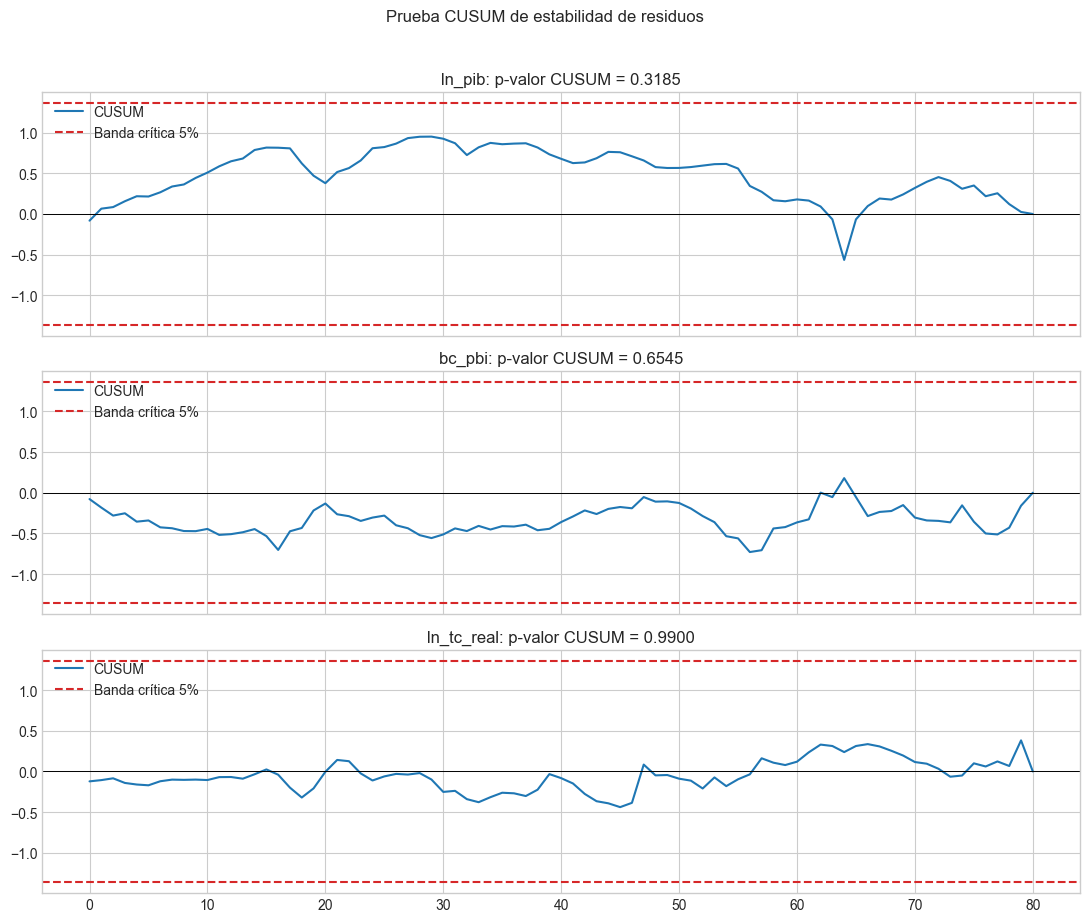

In [67]:
from statsmodels.stats.diagnostic import breaks_cusumolsresid

# Se aplica CUSUM por ecuación usando los residuos del modelo final.
residuals = pd.DataFrame(fitted.resid, columns=ENDOGENOUS).dropna()
cusum_rows = []
fig, axes = plt.subplots(len(ENDOGENOUS), 1, figsize=(11, 9), sharex=True)
axes = np.atleast_1d(axes)

for ax, variable in zip(axes, ENDOGENOUS):
    resid = residuals[variable].to_numpy()
    sup_b, p_value, critical = breaks_cusumolsresid(resid, ddof=0)
    cusum = np.cumsum(resid - resid.mean()) / (np.std(resid, ddof=1) * np.sqrt(len(resid)))
    time_index = residuals.index
    ax.plot(time_index, cusum, color='tab:blue', label='CUSUM')
    critical_5 = next(value for significance, value in critical if significance == 5)
    ax.axhline(critical_5, color='tab:red', linestyle='--', label='Banda crítica 5%')
    ax.axhline(-critical_5, color='tab:red', linestyle='--')
    ax.axhline(0, color='black', linewidth=0.7)
    ax.set_title(f'{variable}: p-valor CUSUM = {p_value:.4f}')
    ax.legend(loc='upper left')
    cusum_rows.append({
        'variable': variable,
        'estadistico_sup_b': float(sup_b),
        'p_valor': float(p_value),
        'critico_5': float(critical_5),
        'evidencia_inestabilidad_5': bool(p_value < 0.05),
    })

fig.suptitle('Prueba CUSUM de estabilidad de residuos', y=1.02)
fig.tight_layout()
fig.savefig(IMG_DIR / 'cusum_estabilidad_residuos.png', dpi=300, bbox_inches='tight')
cusum_table = pd.DataFrame(cusum_rows)
cusum_table.to_csv(RESULTS_DIR / 'diagnostico_cusum.csv', index=False)
display(cusum_table)
plt.show()

## 7. Objetivos 2 y 3: causalidad, IRF y FEVD

### Causalidad de Granger

Para evaluar si la balanza comercial ayuda a predecir el PBI:

- **H0:** la balanza comercial no causa al PBI en sentido de Granger.
- **H1:** la balanza comercial sí aporta capacidad predictiva al PBI.

Para evaluar si el PBI ayuda a predecir la balanza comercial:

- **H0:** el PBI no causa a la balanza comercial en sentido de Granger.
- **H1:** el PBI sí aporta capacidad predictiva a la balanza comercial.

En ambos casos:

- Si `p < 0.05`, se rechaza H0.
- Si `p >= 0.05`, no se rechaza H0.

La causalidad de Granger se interpreta como capacidad predictiva, no como causalidad estructural definitiva. La interpretación de cada p-valor se imprime en la consola después del resultado.

Granger causality F-test. H_0: bc_pbi does not Granger-cause ln_pib. Conclusion: fail to reject H_0 at 5% significance level.
Test statistic Critical value p-value    df   
----------------------------------------------
        0.5910          3.885   0.443 (1, 216)
----------------------------------------------
p=0.4429 -> no rechazar H0: no hay evidencia de causalidad predictiva BC/PBI -> PBI.
Granger causality F-test. H_0: ln_pib does not Granger-cause bc_pbi. Conclusion: reject H_0 at 5% significance level.
Test statistic Critical value p-value    df   
----------------------------------------------
         6.460          3.885   0.012 (1, 216)
----------------------------------------------
p=0.0117 -> rechazar H0: evidencia de causalidad predictiva PBI -> BC/PBI.
alpha (ajuste hacia el equilibrio de largo plazo):


,CE1
ln_pib,-0.045128
bc_pbi,-0.135447
ln_tc_real,-0.313785


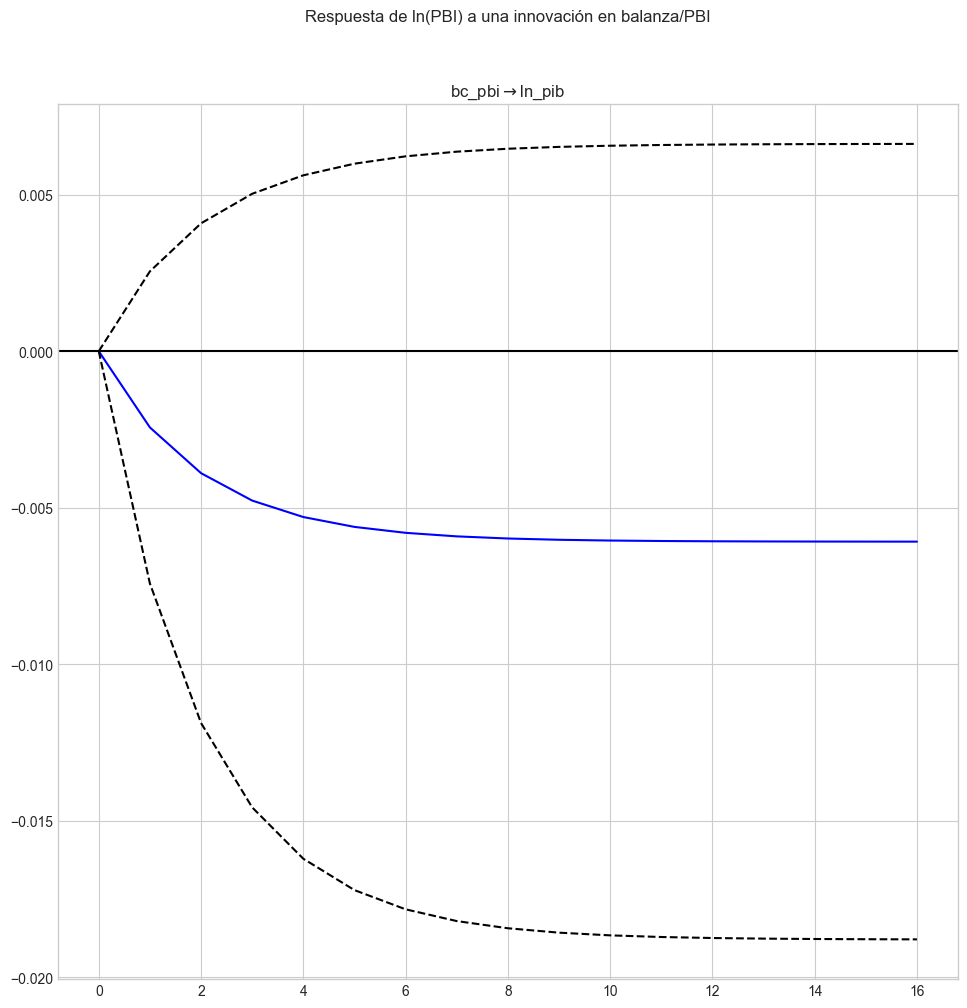

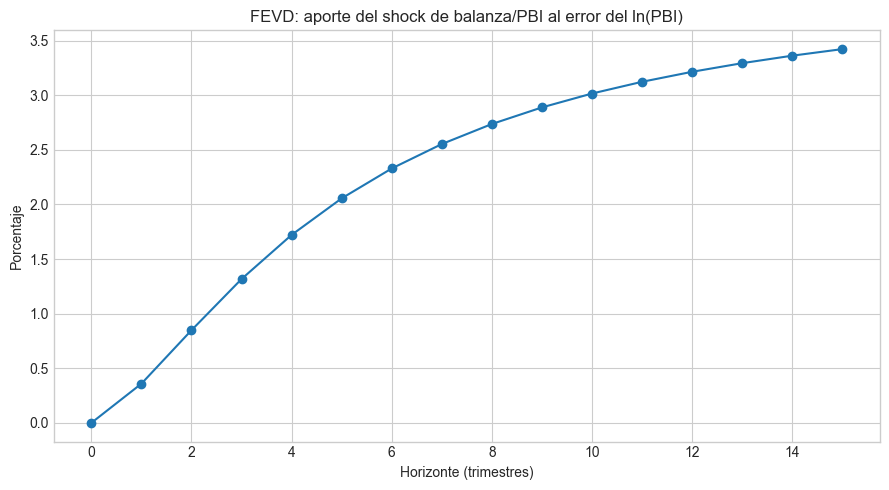

IRF y FEVD guardadas en: C:\Users\atili\OneDrive - unsa.edu.pe\UNSA\SEMESTER 6\ECONOMY INTERNATIONAL\TIF\python\results\img


In [68]:
HORIZON = 16
ORDER = ENDOGENOUS.copy()

if model_kind.startswith('VAR'):
    granger_bc_pib = fitted.test_causality('ln_pib', ['bc_pbi'], kind='f')
    granger_pib_bc = fitted.test_causality('bc_pbi', ['ln_pib'], kind='f')
else:
    granger_bc_pib = fitted.test_granger_causality(causing=['bc_pbi'], caused='ln_pib', signif=0.05)
    granger_pib_bc = fitted.test_granger_causality(causing=['ln_pib'], caused='bc_pbi', signif=0.05)
print(granger_bc_pib.summary())
print(f'p={granger_bc_pib.pvalue:.4f} -> ' + ('rechazar H0: evidencia de causalidad predictiva BC/PBI -> PBI.' if granger_bc_pib.pvalue < 0.05 else 'no rechazar H0: no hay evidencia de causalidad predictiva BC/PBI -> PBI.'))
print(granger_pib_bc.summary())
print(f'p={granger_pib_bc.pvalue:.4f} -> ' + ('rechazar H0: evidencia de causalidad predictiva PBI -> BC/PBI.' if granger_pib_bc.pvalue < 0.05 else 'no rechazar H0: no hay evidencia de causalidad predictiva PBI -> BC/PBI.'))
print('alpha (ajuste hacia el equilibrio de largo plazo):')
display(pd.DataFrame(fitted.alpha, index=ENDOGENOUS, columns=[f'CE{i+1}' for i in range(fitted.alpha.shape[1])]))

irf = fitted.irf(HORIZON)
fig = irf.plot(orth=True, impulse='bc_pbi' if model_kind.startswith('VAR') else 1, response='ln_pib' if model_kind.startswith('VAR') else 0)
fig.suptitle('Respuesta de ln(PBI) a una innovación en balanza/PBI', y=1.02)
fig.savefig(IMG_DIR / 'irf_bc_pbi_sobre_pib.png', dpi=300, bbox_inches='tight')
plt.show()

def fevd_from_var_rep(model, horizon, names):
    coefs = np.asarray(model.coefs if hasattr(model, 'coefs') else model.var_rep)
    sigma = np.asarray(model.sigma_u)
    p, k, _ = coefs.shape
    chol = np.linalg.cholesky(sigma)
    psi = [np.eye(k)]
    for h in range(1, horizon):
        value = np.zeros((k, k))
        for lag in range(1, min(p, h) + 1):
            value += coefs[lag - 1] @ psi[h - lag]
        psi.append(value)
    shares = np.zeros((horizon, k, k))
    for h in range(horizon):
        total = np.zeros((k, k))
        for step in range(h + 1):
            impact = psi[step] @ chol
            total += impact ** 2
        shares[h] = total / total.sum(axis=1, keepdims=True) * 100
    rows = []
    for h in range(horizon):
        for response in range(k):
            for shock in range(k):
                rows.append({'horizonte': h, 'respuesta': names[response], 'shock': names[shock], 'porcentaje': shares[h, response, shock]})
    return pd.DataFrame(rows)

fevd_table = fevd_from_var_rep(fitted, HORIZON, ORDER)
fevd_table.to_csv(RESULTS_DIR / 'fevd.csv', index=False) if 'RESULTS_DIR' in globals() else None
pbi_fevd = fevd_table[(fevd_table['respuesta'] == 'ln_pib') & (fevd_table['shock'] == 'bc_pbi')]
fig, ax = plt.subplots(figsize=(9, 5))
ax.plot(pbi_fevd['horizonte'], pbi_fevd['porcentaje'], marker='o')
ax.set(title='FEVD: aporte del shock de balanza/PBI al error del ln(PBI)', xlabel='Horizonte (trimestres)', ylabel='Porcentaje')
fig.tight_layout()
fig.savefig(IMG_DIR / 'fevd_bc_pbi_sobre_pib.png', dpi=300, bbox_inches='tight')
plt.show()
print('IRF y FEVD guardadas en:', IMG_DIR.resolve())

## 8. Exportación y robustez

Las conclusiones deben repetirse con: (i) `tc_real alternativo` en lugar de `tc_real`; (ii) VAR en diferencias si no hay cointegración; (iii) órdenes recursivos alternativos; y (iv) dummies de ruptura validadas. No se deben incluir simultáneamente las dos versiones del tipo de cambio real.

## 8. Base final, rezagos y predicción fuera de muestra
Se reservan los últimos ocho trimestres para evaluar capacidad predictiva. La base de rezagos se construye solo con la muestra de entrenamiento y documenta las variables y el úmero de rezagos seleccionados. Al final de esta sección, el notebook exporta `resumen_pruebas.txt`, un archivo de texto con las pruebas y diagnósticos principales para consulta rápida.

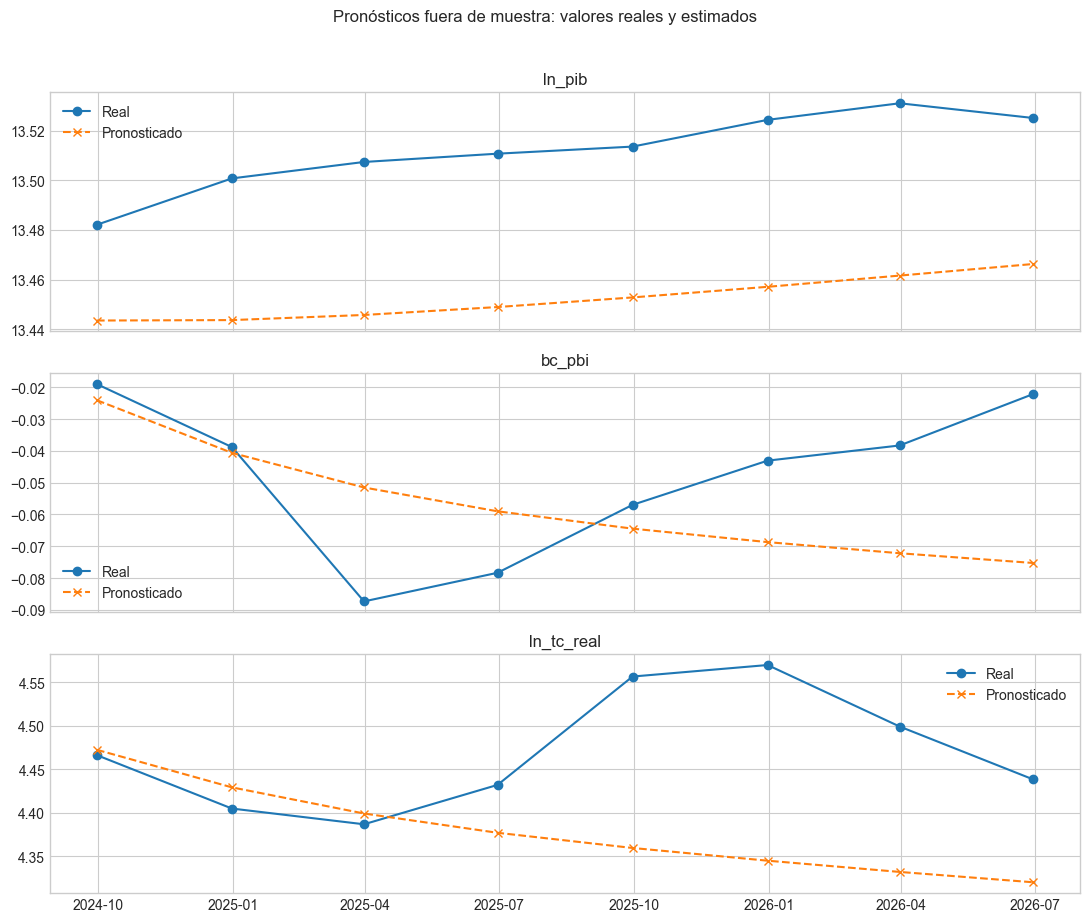

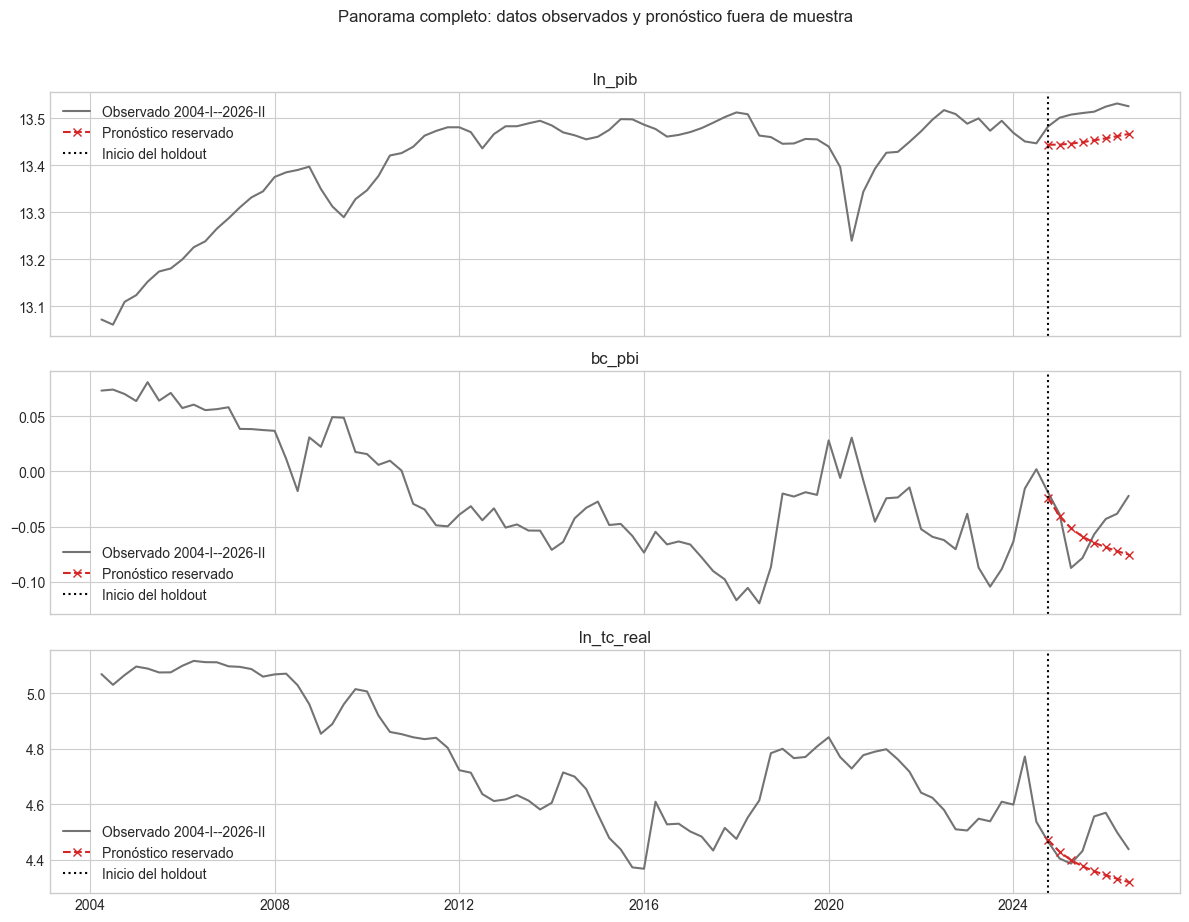

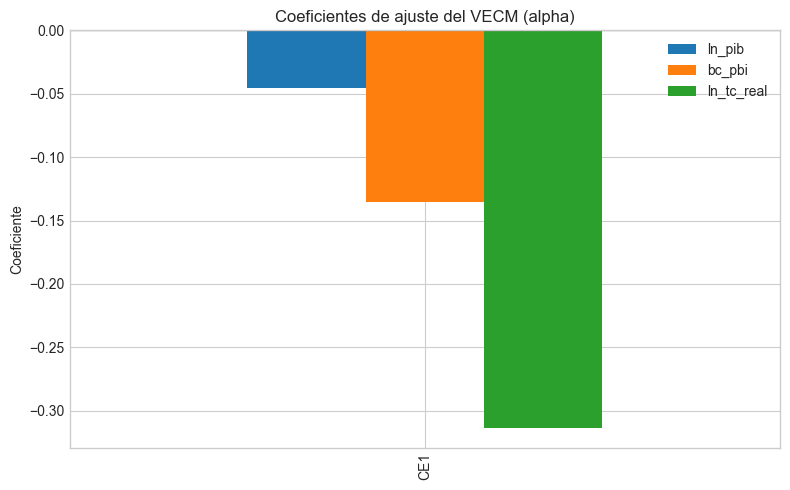

Resultados exportados en: C:\Users\atili\OneDrive - unsa.edu.pe\UNSA\SEMESTER 6\ECONOMY INTERNATIONAL\TIF\python\results
Rezagos utilizados: 1 | variables: ['ln_pib', 'bc_pbi', 'ln_tc_real'] | exógenas: ['covid']
Holdout reservado: 8 trimestres


In [69]:
## Exportación de la base final, rezagos y evaluación fuera de muestra
# La carpeta se crea junto al notebook, independientemente del directorio desde el que se ejecute.
RESULTS_DIR = DATA_PATH.parent.parent / 'python' / 'results'
RESULTS_DIR.mkdir(parents=True, exist_ok=True)
IMG_DIR = RESULTS_DIR / 'img'
IMG_DIR.mkdir(exist_ok=True)
for old_file in ['series_modelo.csv', 'fevd.csv', 'criterios_rezagos.csv', 'metricas_pronostico.csv', 'data_modelo_holdout.csv', 'resumen_modelo.tex', 'resumen_modelo.txt', 'resumen_pruebas.txt', 'tabla_coeficientes_var.tex', 'tabla_coeficientes_var.csv', 'coeficientes_ajuste_alpha.csv', 'pvalores_ajuste_alpha.csv']:
    old_path = RESULTS_DIR / old_file
    if old_path.exists():
        old_path.unlink()
for old_image in ['Figure_1.png', 'Figure_2.png']:
    old_path = IMG_DIR / old_image
    if old_path.exists():
        old_path.unlink()

# Base transformada completa, identificando entrenamiento y holdout.
model_data = df[ENDOGENOUS + EXOGENOUS].copy()
model_data['muestra'] = np.where(model_data.index.isin(train_df.index), 'entrenamiento', 'holdout')
model_data.to_csv(RESULTS_DIR / 'data_modelo_completa.csv', index_label='fecha')
train_df[ENDOGENOUS + EXOGENOUS].to_csv(RESULTS_DIR / 'data_modelo_entrenamiento.csv', index_label='fecha')

# Tabla descriptiva de las variables del sistema, generada en formato LaTeX.
descriptive = train_series.describe().T.rename(columns={'count': 'N', 'mean': 'Media', 'std': 'Desv. est.', 'min': 'Min.', 'max': 'Max.'})[['N', 'Media', 'Desv. est.', 'Min.', 'Max.']]
with open(RESULTS_DIR / 'estadisticas_descriptivas.tex', 'w', encoding='utf-8') as output:
    output.write('\\begin{table}[H]\n\\centering\n')
    output.write('\\caption{Estadisticas descriptivas de la muestra de entrenamiento}\n')
    output.write('\\begin{tabular}{lrrrrr}\n\\toprule\nVariable & N & Media & Desv. est. & Min. & Max. \\\\\n\\midrule\n')
    for variable, row in descriptive.iterrows():
        latex_variable = variable.replace('_', '\\_')
        output.write(f'{latex_variable} & {int(row["N"])} & {row["Media"]:.4f} & {row["Desv. est."]:.4f} & {row["Min."]:.4f} & {row["Max."]:.4f} \\\\\n')
    output.write('\\bottomrule\n\\end{tabular}\n\\end{table}\n')

# Tabla explícita de rezagos de las variables endógenas de la estimación.
lagged = train_series.copy()
for lag in range(1, selected_lag + 1):
    for col in ENDOGENOUS:
        lagged[f'{col}_L{lag}'] = train_series[col].shift(lag)
lagged = lagged.dropna()
lagged.to_csv(RESULTS_DIR / 'data_modelo_rezagos.csv', index_label='fecha')

# Pronóstico reservado: los últimos HOLDOUT_QUARTERS no participan en la estimación.
forecast_frame = pd.DataFrame(index=test_df.index)
if model_kind == 'VAR_niveles_rango_completo':
    forecast_values = fitted.forecast(y=train_series.to_numpy()[-fitted.k_ar:], steps=HOLDOUT_QUARTERS, exog_future=test_exog.to_numpy())
    forecast_frame = pd.DataFrame(forecast_values, index=test_df.index, columns=ENDOGENOUS)
    for col in ENDOGENOUS:
        forecast_frame[f'{col}_real'] = test_series[col]
        forecast_frame[f'{col}_error'] = forecast_frame[f'{col}_real'] - forecast_frame[col]
    forecast_frame.to_csv(RESULTS_DIR / 'pronostico_holdout.csv', index_label='fecha')
elif model_kind == 'VECM':
    forecast_values = fitted.predict(steps=HOLDOUT_QUARTERS, exog_fc=test_exog.to_numpy())
    forecast_frame = pd.DataFrame(forecast_values, index=test_df.index, columns=ENDOGENOUS)
    for col in ENDOGENOUS:
        forecast_frame[f'{col}_real'] = test_series[col]
        forecast_frame[f'{col}_error'] = forecast_frame[f'{col}_real'] - forecast_frame[col]
    forecast_frame.to_csv(RESULTS_DIR / 'pronostico_holdout.csv', index_label='fecha')
else:
    # En VAR en diferencias, el archivo conserva el pronóstico de diferencias; no se compara con niveles.
    forecast_values = fitted.forecast(y=diff_series.to_numpy()[-fitted.k_ar:], steps=HOLDOUT_QUARTERS, exog_future=test_exog.to_numpy())
    pd.DataFrame(forecast_values, index=test_df.index, columns=ENDOGENOUS).to_csv(RESULTS_DIR / 'pronostico_holdout_diferencias.csv', index_label='fecha')

if not forecast_frame.empty:
    metric_rows = []
    for col in ENDOGENOUS:
        errors = forecast_frame[f'{col}_error'].to_numpy()
        actual = forecast_frame[f'{col}_real'].to_numpy()
        nonzero = np.abs(actual) > 1e-12
        metric_rows.append({
            'variable': col,
            'RMSE': float(np.sqrt(np.mean(errors ** 2))),
            'MAE': float(np.mean(np.abs(errors))),
            'MAPE': float(np.mean(np.abs(errors[nonzero] / actual[nonzero])) * 100) if nonzero.any() else np.nan,
            'observaciones_holdout': int(len(actual)),
        })
    pd.DataFrame(metric_rows).to_csv(RESULTS_DIR / 'metricas_pronostico.csv', index=False)

criteria = pd.DataFrame({
    'criterio': ['AIC', 'BIC', 'HQIC', 'FPE'],
    'rezago_seleccionado': [lag_selection.aic, lag_selection.bic, lag_selection.hqic, lag_selection.fpe],
    'rezago_final_usado': [selected_lag] * 4,
})
criteria.to_csv(RESULTS_DIR / 'criterios_rezagos.csv', index=False)

break_diagnostic = pd.DataFrame({
    'variable': list(break_dates.keys()),
    'fecha_sugerida_Zivot_Andrews': [pd.Timestamp(value).date().isoformat() for value in break_dates.values()],
    'interpretacion': 'Diagnóstico de ruptura endógena; no implica por sí solo incorporar una dummy.'
})
break_diagnostic.to_csv(RESULTS_DIR / 'diagnostico_rupturas.csv', index=False)

metadata = {
    'variables_endogenas': ENDOGENOUS,
    'variables_exogenas': EXOGENOUS,
    'modelo': model_kind,
    'rezagos_VAR': int(selected_lag),
    'rezagos_diferencias_VECM': int(k_ar_diff) if model_kind == 'VECM' else 0,
    'rango_Johansen': int(rank),
    'observaciones_totales': int(len(df)),
    'observaciones_entrenamiento': int(len(train_df)),
    'observaciones_holdout': int(len(test_df)),
    'inicio_entrenamiento': str(train_df.index.min().date()),
    'fin_entrenamiento': str(train_df.index.max().date()),
    'inicio_holdout': str(test_df.index.min().date()),
    'fin_holdout': str(test_df.index.max().date()),
    'covid_incluido_como_exogena': True,
    'períodos_covid_activos': ', '.join(df.index[df['covid'].eq(1)].strftime('%Y-%m-%d')),
    'ruptura_estructural': 'Se diagnostica con Zivot-Andrews; COVID se controla con dummy de pulso 2020-II y 2020-III.',
}
pd.Series(metadata, dtype='object').to_csv(RESULTS_DIR / 'metadatos_modelo.csv', header=['valor'])

# Exportaciones adicionales para el informe LaTeX.
ur_export = []
for variable, table in ur_tables.items():
    table_export = table.reset_index().rename(columns={'index': 'prueba'})
    table_export.insert(0, 'variable', variable)
    ur_export.append(table_export)
pd.concat(ur_export, ignore_index=True).to_csv(RESULTS_DIR / 'pruebas_raiz_unitaria.csv', index=False)
johansen_table.to_csv(RESULTS_DIR / 'cointegracion_johansen.csv', index=False)
# Resumen legible de todas las pruebas principales para consulta rápida.
test_sections = []
test_sections.append('RESUMEN DE PRUEBAS ECONOMÉTRICAS\n' + '=' * 80)
test_sections.append(f'BASE: {len(df)} observaciones trimestrales, {df.index.min().date()} a {df.index.max().date()}')
test_sections.append(f'MUESTRA DE ENTRENAMIENTO: {len(train_df)} observaciones; HOLDOUT: {len(test_df)} observaciones')
test_sections.append('\n1. PRUEBAS DE RAÍZ UNITARIA\n' + '-' * 80)
for variable, table in ur_tables.items():
    test_sections.append(f'\n{variable}\n{table.to_string()}' )
test_sections.append('\n\n2. RUPTURAS ESTRUCTURALES: ZIVOT-ANDREWS\n' + '-' * 80)
test_sections.append(break_diagnostic.to_string(index=False))
test_sections.append('\n\n3. SELECCIÓN DE REZAGOS\n' + '-' * 80)
test_sections.append(criteria.to_string(index=False))
test_sections.append('\n\n4. COINTEGRACIÓN DE JOHANSEN\n' + '-' * 80)
test_sections.append(johansen_table.to_string(index=False))
test_sections.append(f'\nRango seleccionado al 5%: {rank}')
test_sections.append('\n\n5. ESTABILIDAD CUSUM\n' + '-' * 80)
test_sections.append(cusum_table.to_string(index=False) if 'cusum_table' in globals() else 'CUSUM no disponible en esta ejecución.')
test_sections.append('\n\n6. DIAGNÓSTICOS DEL MODELO\n' + '-' * 80)
test_sections.append(f'Modelo: {model_kind}')
test_sections.append(f'Es estable: {fitted.is_stable() if model_kind.startswith("VAR") else "no aplica como prueba VAR"}')
if model_kind.startswith('VAR'):
    test_sections.append('\nPrueba de autocorrelación (whiteness, 4 rezagos):\n' + str(fitted.test_whiteness(nlags=4).summary()))
    test_sections.append('\nPrueba de normalidad de residuos:\n' + str(fitted.test_normality().summary()))
    test_sections.append('\nCausalidad de Granger: BC/PBI -> ln(PBI)\n' + str(fitted.test_causality('ln_pib', ['bc_pbi'], kind='f').summary()))
    test_sections.append('\nCausalidad de Granger: ln(PBI) -> BC/PBI\n' + str(fitted.test_causality('bc_pbi', ['ln_pib'], kind='f').summary()))
else:
    test_sections.append('\nCausalidad de Granger: BC/PBI -> ln(PBI)\n' + str(fitted.test_granger_causality(causing=['bc_pbi'], caused='ln_pib', signif=0.05).summary()))
    test_sections.append('\nCausalidad de Granger: ln(PBI) -> BC/PBI\n' + str(fitted.test_granger_causality(causing=['ln_pib'], caused='bc_pbi', signif=0.05).summary()))
with open(RESULTS_DIR / 'resumen_pruebas.txt', 'w', encoding='utf-8') as output:
    output.write('\n\n'.join(test_sections) + '\n')
if model_kind == 'VECM':
    alpha_table = pd.DataFrame(fitted.alpha, index=ENDOGENOUS, columns=[f'CE{i+1}' for i in range(fitted.alpha.shape[1])])
    alpha_table.to_csv(RESULTS_DIR / 'coeficientes_ajuste_alpha.csv')
    alpha_pvalues = pd.DataFrame(fitted.pvalues_alpha, index=ENDOGENOUS, columns=alpha_table.columns)
    alpha_pvalues.to_csv(RESULTS_DIR / 'pvalores_ajuste_alpha.csv')
    with open(RESULTS_DIR / 'resumen_modelo.tex', 'w', encoding='utf-8') as output:
        output.write(fitted.summary().as_latex())
else:
    params = fitted.params
    stderr = fitted.stderr
    pvalues = fitted.pvalues
    coefficient_rows = []
    for term in params.index:
        row = {'termino': term}
        for equation in ENDOGENOUS:
            p_value = float(pvalues.loc[term, equation])
            stars = '***' if p_value < 0.01 else '**' if p_value < 0.05 else '*' if p_value < 0.10 else ''
            row[f'{equation}_coef'] = float(params.loc[term, equation])
            row[f'{equation}_se'] = float(stderr.loc[term, equation])
            row[f'{equation}_p'] = p_value
            row[f'{equation}_stars'] = stars
        coefficient_rows.append(row)
    coefficient_table = pd.DataFrame(coefficient_rows)
    coefficient_table.to_csv(RESULTS_DIR / 'tabla_coeficientes_var.csv', index=False)
    with open(RESULTS_DIR / 'tabla_coeficientes_var.tex', 'w', encoding='utf-8') as output:
        output.write('\\begin{table}[H]\n\\centering\n\\caption{Resultados del VAR: coeficientes y significancia}\n')
        output.write('\\begin{tabular}{lccc}\n\\toprule\n')
        output.write(' & \\multicolumn{1}{c}{ln(PBI)} & \\multicolumn{1}{c}{BC/PBI} & \\multicolumn{1}{c}{ln(TC real)} \\\\\n\\midrule\n')
        for _, row in coefficient_table.iterrows():
            label = str(row['termino']).replace('_', '\\_')
            output.write(label + ' & ' + ' & '.join(f'{row[f"{eq}_coef"]:.4f}{row[f"{eq}_stars"]}' for eq in ENDOGENOUS) + ' \\\\\n')
            output.write(' & ' + ' & '.join(f'({row[f"{eq}_se"]:.4f})' for eq in ENDOGENOUS) + ' \\\\\n')
        output.write('\\midrule\nObservaciones & \\multicolumn{3}{c}{' + str(int(fitted.nobs)) + '} \\\\\n')
        output.write('\\bottomrule\n\\end{tabular}\n')
        output.write('\\begin{flushleft}\\footnotesize Errores estandar entre parentesis. * $p<0.10$, ** $p<0.05$, *** $p<0.01$.\\end{flushleft}\n\\end{table}\n')
    with open(RESULTS_DIR / 'resumen_modelo.txt', 'w', encoding='utf-8') as output:
        output.write(str(fitted.summary()))
    with open(RESULTS_DIR / 'resumen_modelo.tex', 'w', encoding='utf-8') as output:
        output.write('\\begin{verbatim}\n')
        output.write(str(fitted.summary()))
        output.write('\\end{verbatim}\n')

if not forecast_frame.empty:
    fig, axes = plt.subplots(len(ENDOGENOUS), 1, figsize=(11, 9), sharex=True)
    axes = np.atleast_1d(axes)
    for ax, col in zip(axes, ENDOGENOUS):
        ax.plot(test_series.index, forecast_frame[f'{col}_real'], marker='o', label='Real')
        ax.plot(test_series.index, forecast_frame[col], marker='x', linestyle='--', label='Pronosticado')
        ax.set_title(col)
        ax.legend()
    fig.suptitle('Pronósticos fuera de muestra: valores reales y estimados', y=1.02)
    fig.tight_layout()
    fig.savefig(IMG_DIR / 'pronostico_real_vs_estimado.png', dpi=300, bbox_inches='tight')
    plt.show()
    fig, axes = plt.subplots(len(ENDOGENOUS), 1, figsize=(12, 9), sharex=True)
    axes = np.atleast_1d(axes)
    for ax, col in zip(axes, ENDOGENOUS):
        ax.plot(df.index, df[col], color='0.45', label='Observado 2004-I--2026-II')
        ax.plot(test_df.index, forecast_frame[col], color='tab:red', marker='x', linestyle='--', label='Pronóstico reservado')
        ax.axvline(test_df.index.min(), color='black', linestyle=':', label='Inicio del holdout')
        ax.set_title(col)
        ax.legend()
    fig.suptitle('Panorama completo: datos observados y pronóstico fuera de muestra', y=1.02)
    fig.tight_layout()
    fig.savefig(IMG_DIR / 'panorama_completo_pronostico.png', dpi=300, bbox_inches='tight')
    plt.show()

if model_kind == 'VECM':
    fig, ax = plt.subplots(figsize=(8, 5))
    alpha_table.T.plot(kind='bar', ax=ax)
    ax.axhline(0, color='black', linewidth=0.8)
    ax.set_title('Coeficientes de ajuste del VECM (alpha)')
    ax.set_ylabel('Coeficiente')
    fig.tight_layout()
    fig.savefig(IMG_DIR / 'coeficientes_ajuste_alpha.png', dpi=300, bbox_inches='tight')
    plt.show()
print('Resultados exportados en:', RESULTS_DIR.resolve())
print('Rezagos utilizados:', selected_lag, '| variables:', ENDOGENOUS, '| exógenas:', EXOGENOUS)
print('Holdout reservado:', HOLDOUT_QUARTERS, 'trimestres')